# **##Data Acquisition**

## **1. Import Library**

In [22]:
# Basic Libraries

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10,5)
plt.rcParams["font.size"] = 11

# Display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Libraries imported successfully.")

Libraries imported successfully.


**2. Data Acquisition**

In [23]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Dataset Path
DATA = "/content/drive/MyDrive/azkeeyy_PatchTST/data/bottom.csv"

df = pd.read_csv(DATA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**3. Inisialisasi Variabel**

In [24]:
TOTAL_ROWS = len(df)
TOTAL_COLUMNS = len(df.columns)

print(f"Rows    : {TOTAL_ROWS}")
print(f"Columns : {TOTAL_COLUMNS}")

Rows    : 25232
Columns : 10


**Reusable Objects**

In [25]:
reusable_objects = [
    "df",
    "missing_summary",
    "duplicate_df",
    "dtype_df",
    "feature_summary",
    "descriptive_statistics",
    "numerical_features",
    "categorical_features",
    "datetime_features"
]
pd.DataFrame({
    "Reusable Variable":
        reusable_objects
})

,Reusable Variable
0,df
1,missing_summary
2,duplicate_df
3,dtype_df
4,feature_summary
5,descriptive_statistics
6,numerical_features
7,categorical_features
8,datetime_features


### **4. Dataset Preview**

In [26]:
df.head()

,Source IP,Destination IP,Source Port,Destination Port,Protocol,Start Time,End Time,Duration,Total Packets,Total Bytes
0,Unknown,Unknown,Unknown,Unknown,ARP,1.678441e+09,1.678446e+09,5439.491381,9738,584280
1,198.18.134.12,198.18.134.11,43396,5502,DATA,1.678441e+09,1.678446e+09,5442.396154,27213,2122614
2,198.18.134.12,198.18.134.11,43396,5502,TCP,1.678441e+09,1.678446e+09,5442.397125,81639,5714730
3,198.18.134.11,198.18.134.12,5502,43396,DATA,1.678441e+09,1.678446e+09,5442.395823,27213,2149827
4,198.18.134.11,198.18.134.12,5502,43396,TCP,1.678441e+09,1.678446e+09,5442.395822,27213,2149827


### **5. Dataset Dimension**

In [27]:
print(f"Rows    : {TOTAL_ROWS}")
print(f"Columns : {TOTAL_COLUMNS}")

Rows    : 25232
Columns : 10


### **6. Feature Information**

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25232 entries, 0 to 25231
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Source IP         25232 non-null  object 
 1   Destination IP    25232 non-null  object 
 2   Source Port       25232 non-null  object 
 3   Destination Port  25232 non-null  object 
 4   Protocol          25232 non-null  object 
 5   Start Time        25232 non-null  float64
 6   End Time          25232 non-null  float64
 7   Duration          25232 non-null  float64
 8   Total Packets     25232 non-null  int64  
 9   Total Bytes       25232 non-null  int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 1.9+ MB


**7. Feature List**

In [29]:
pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.values
})

descriptive_statistics = df.describe().T
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Source IP,25232,21,198.18.134.99,23084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination IP,25232,17,198.18.134.49,10152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source Port,25232,1607,22,1921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination Port,25232,2587,22,2984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Protocol,25232,12,TCP,23280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Start Time,25232.0,NaN,NaN,NaN,1678444070.809134,1495.323689,1678440574.078823,1678442617.295282,1678444821.380928,1678445124.046986,1678445969.972941
End Time,25232.0,NaN,NaN,NaN,1678444077.384978,1492.100808,1678440583.353598,1678442617.885701,1678444821.573685,1678445124.144872,1678446016.482666
Duration,25232.0,NaN,NaN,NaN,6.575844,173.788602,0.0,0.0,0.0,0.0,5442.397125
Total Packets,25232.0,NaN,NaN,NaN,59.995839,2760.520445,1.0,1.0,1.0,1.0,242878.0
Total Bytes,25232.0,NaN,NaN,NaN,4506.326768,200608.188315,60.0,62.0,62.0,62.0,17009544.0


**8. Feature Grouping**

In [30]:
numerical_features = df.select_dtypes(
    include=["int64","float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

datetime_features = df.select_dtypes(
    include=["datetime64"]
).columns.tolist()

# **##EDA(Exploratory Data Analysis)**

**1. Duplicates Check**

In [31]:
duplicate_count = df.duplicated().sum()

duplicate_percentage = round(
    duplicate_count
    /
    TOTAL_ROWS
    *100,
    2
)

duplicate_df = pd.DataFrame({
    "Duplicate Rows":[duplicate_count],
    "Percentage (%)":[duplicate_percentage]
})

duplicate_df

,Duplicate Rows,Percentage (%)
0,0,0.0


**2. Missing Value**

In [32]:
missing_summary = pd.DataFrame({

    "Missing Values": df.isnull().sum(),

    "Percentage (%)":
    (
        df.isnull().sum()
        /
        TOTAL_ROWS
        *100
    ).round(2)

})

missing_summary

,Missing Values,Percentage (%)
Source IP,0,0.0
Destination IP,0,0.0
Source Port,0,0.0
Destination Port,0,0.0
Protocol,0,0.0
Start Time,0,0.0
End Time,0,0.0
Duration,0,0.0
Total Packets,0,0.0
Total Bytes,0,0.0


**3.Data Type Verification**

In [33]:
dtype_df = pd.DataFrame({

    "Feature":df.columns,

    "Data Type":df.dtypes.values,

    "Unique Values":df.nunique().values,

    "Missing Values":missing_summary["Missing Values"].values

})

**4. Feature Category Summary**

In [34]:
feature_summary = pd.DataFrame({
    "Feature Category":[
        "Numerical",
        "Categorical",
        "Datetime"
    ],
    "Count":[
        len(numerical_features),
        len(categorical_features),
        len(datetime_features)
    ]
})
feature_summary

,Feature Category,Count
0,Numerical,5
1,Categorical,5
2,Datetime,0


**5. Dataset Summary**

In [35]:
dataset_summary = {
    "Rows":TOTAL_ROWS,
    "Columns":TOTAL_COLUMNS,
    "Numerical Features":len(numerical_features),
    "Categorical Features":len(categorical_features),
    "Datetime Features":len(datetime_features),
    "Duplicate Rows":duplicate_count
}

pd.DataFrame(
    dataset_summary,
    index=["Summary"]
)

,Rows,Columns,Numerical Features,Categorical Features,Datetime Features,Duplicate Rows
Summary,25232,10,5,5,0,0


**6. Descriptive_statistics**

In [36]:
display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max
Start Time,25232.0,1.678444e+09,1495.323689,1.678441e+09,1.678443e+09,1.678445e+09,1.678445e+09,1.678446e+09
End Time,25232.0,1.678444e+09,1492.100808,1.678441e+09,1.678443e+09,1.678445e+09,1.678445e+09,1.678446e+09
Duration,25232.0,6.575844e+00,173.788602,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.442397e+03
Total Packets,25232.0,5.999584e+01,2760.520445,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.428780e+05
Total Bytes,25232.0,4.506327e+03,200608.188315,6.000000e+01,6.200000e+01,6.200000e+01,6.200000e+01,1.700954e+07


**7. Numerical Feature Distribution**

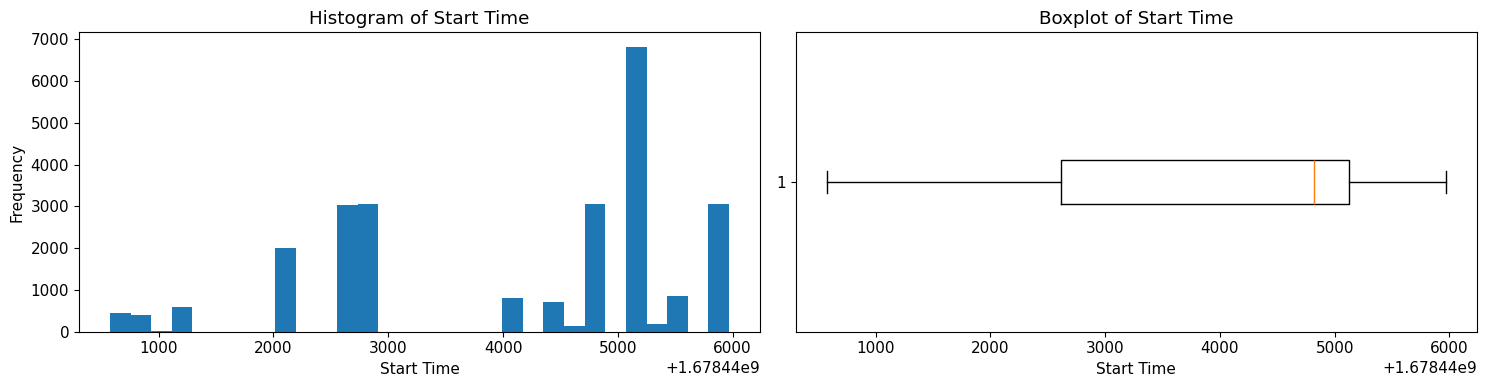

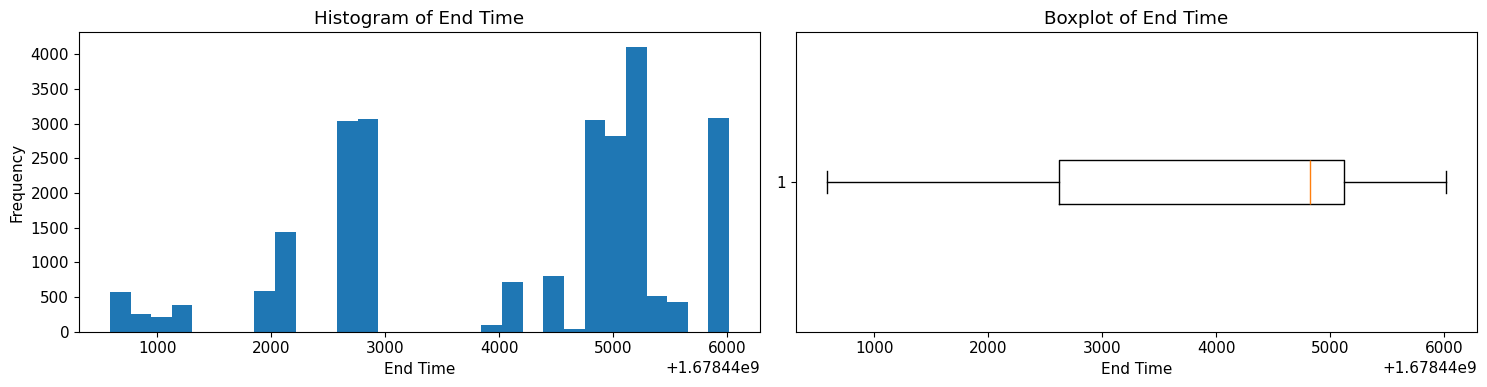

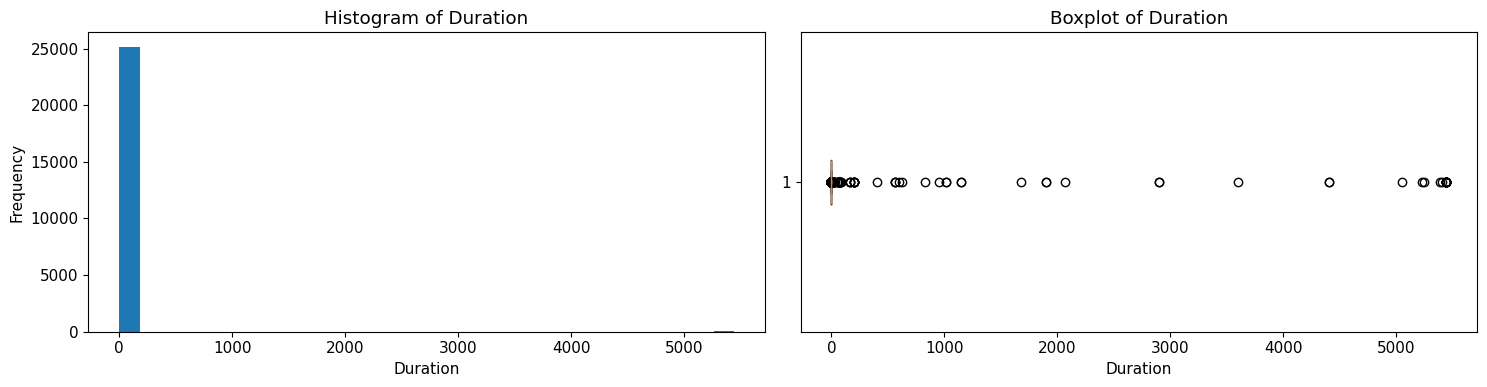

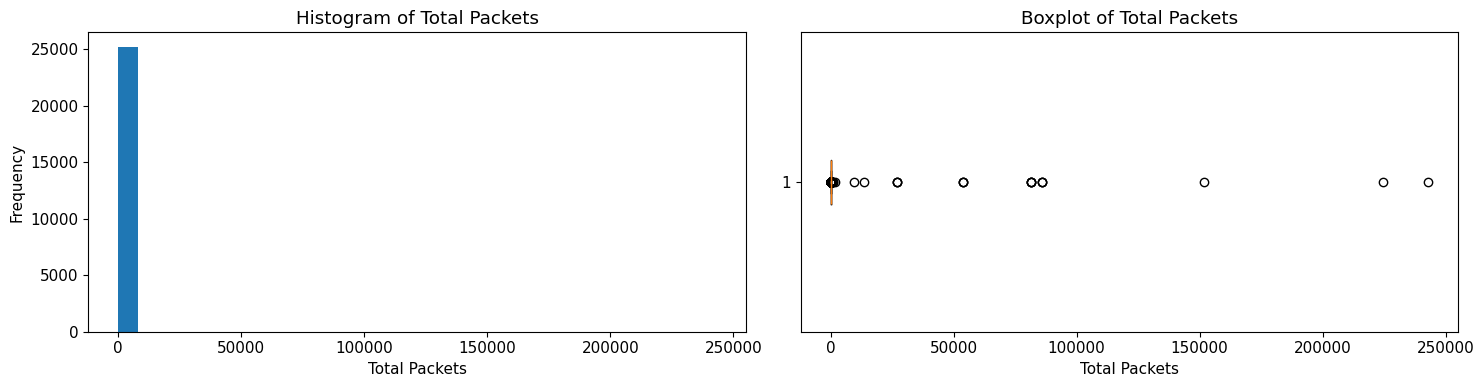

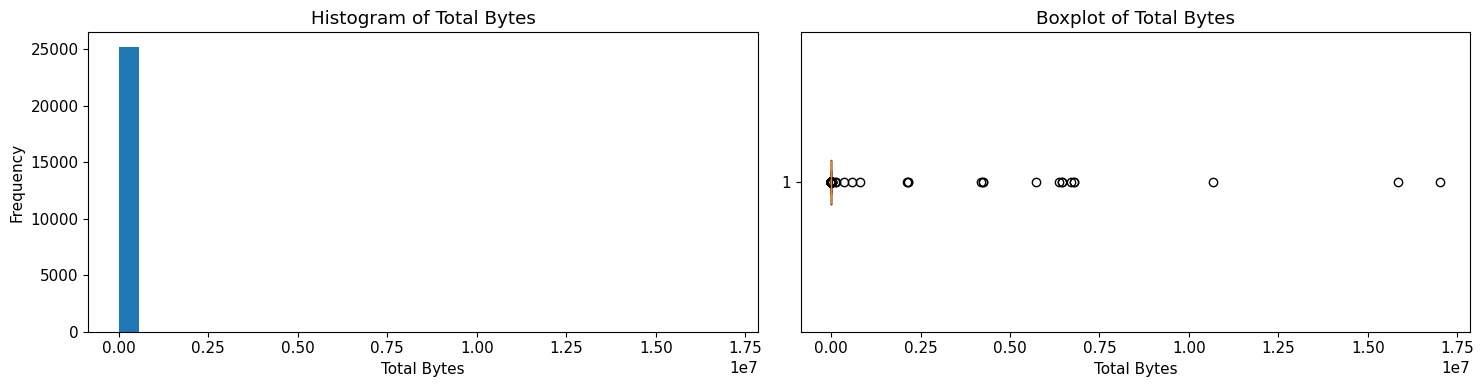

In [37]:
def plot_numerical_distribution(dataframe, feature):

    fig, axes = plt.subplots(1,2, figsize=(15,4))

    # Histogram
    axes[0].hist(
        dataframe[feature].dropna(),
        bins=30
    )
    axes[0].set_title(f"Histogram of {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    axes[1].boxplot(
        dataframe[feature].dropna(),
        vert=False
    )
    axes[1].set_title(f"Boxplot of {feature}")
    axes[1].set_xlabel(feature)

    plt.tight_layout()

    plt.show()

for feature in numerical_features:
      plot_numerical_distribution(df, feature)

**8. Categorical Feature Distribution**

,Frequency
Source IP,
198.18.134.99,23084
198.18.134.49,780
198.18.134.47,683
198.18.134.6,326
198.18.134.38,235
...,...
198.134.18.38,1
198.134.18.47,1
198.134.18.42,1


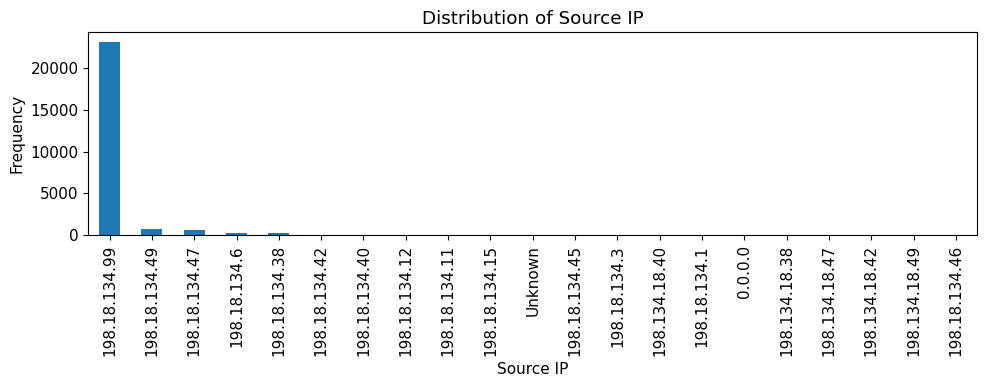

,Frequency
Destination IP,
198.18.134.49,10152
198.18.134.42,6042
198.18.134.47,4026
198.18.134.99,2097
198.18.134.40,2004
198.18.134.6,500
198.18.134.38,356
224.0.0.22,14
198.18.134.11,10


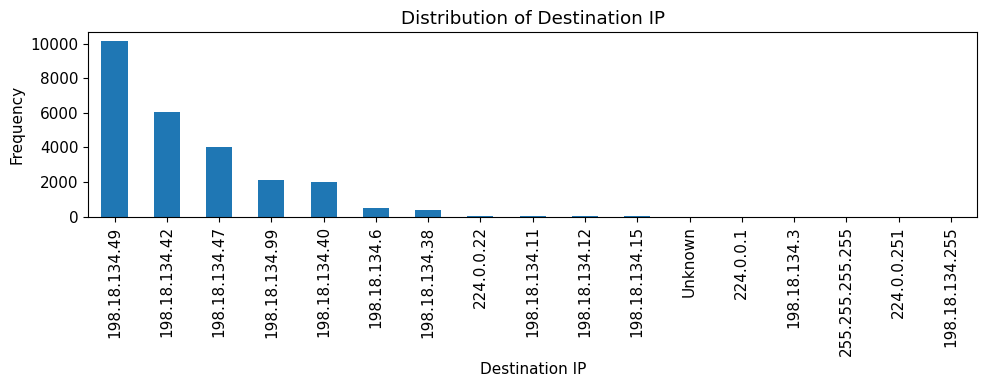

,Frequency
Source Port,
22,1921
47153,1000
58255,1000
38634,1000
45074,1000
...,...
45153,1
45154,1
45155,1


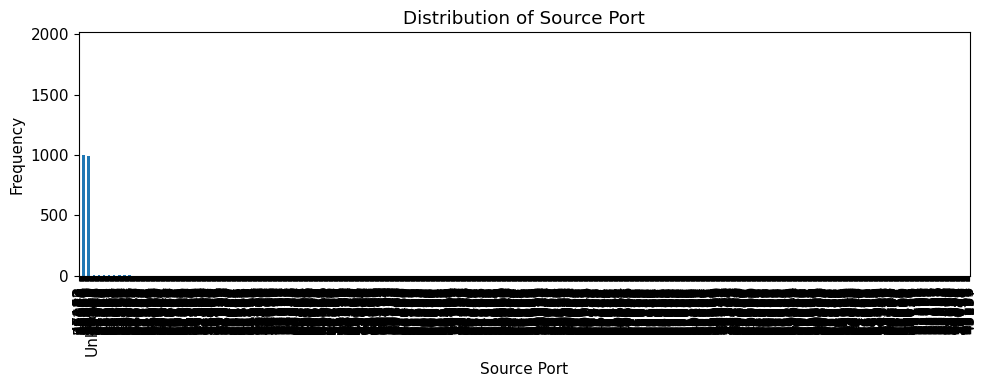

,Frequency
Destination Port,
22,2984
80,93
443,73
49160,22
Unknown,22
...,...
45150,1
45149,1
45148,1


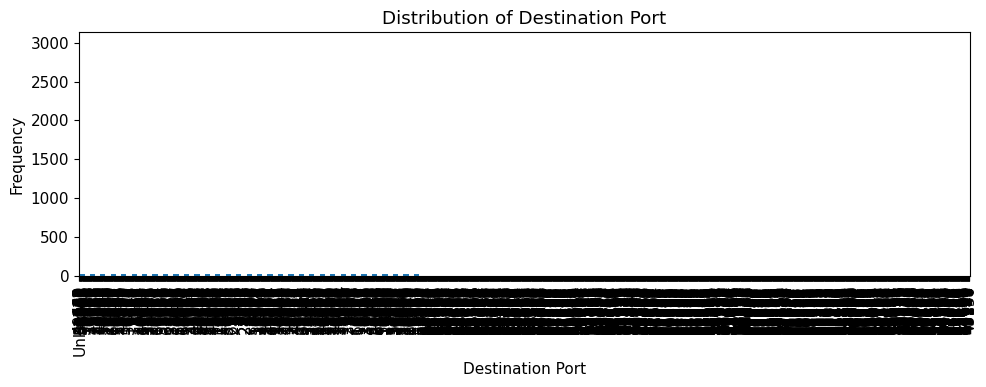

,Frequency
Protocol,
TCP,23280
SSH,1905
IGMP,18
DATA,9
_WS.MALFORMED,8
THRIFT,6
STP,1
ARP,1
DHCP,1


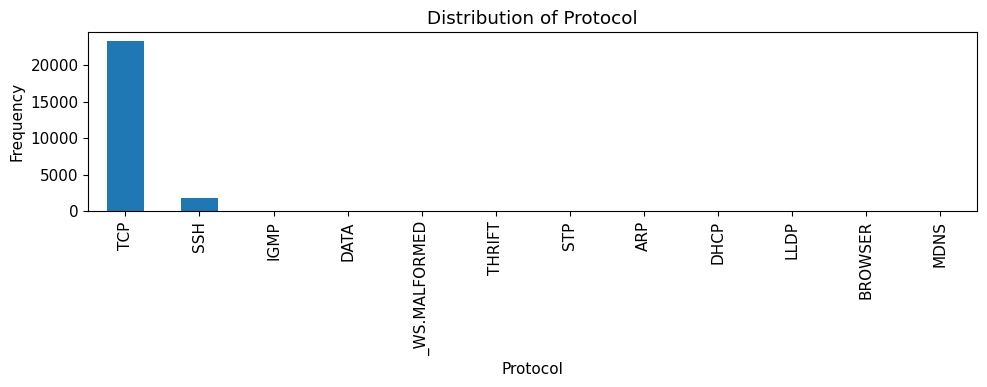

In [38]:
def plot_categorical_distribution(dataframe, feature):
    counts = dataframe[feature].value_counts()
    display(counts.to_frame(name="Frequency"))
    plt.figure(figsize=(10,4))
    counts.plot(kind="bar")
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

for feature in categorical_features:
  plot_categorical_distribution(df, feature)